# Chapitre 11 - Cours 6 : raisonner sur le temps

« La moyenne des cinq dernières minutes » : l'expression paraît limpide. Elle est en
réalité piégeuse dès que les événements arrivent en retard, dans le désordre, ou
horodatés par des horloges peu fiables. Ce notebook couvre la sous-section *Reasoning
About Time* : *Event time versus processing time*, *Knowing when you're ready*, *Whose clock
are you using, anyway?* et *Types of windows*. Les fonctions de fenêtrage et le compteur
à filigrane sont dans [`ddia/streams.py`](../../ddia/streams.py).

**Plan.**

1. Temps de l'événement contre temps de traitement.
2. Les retardataires : quand une fenêtre est-elle complète ? (filigranes)
3. L'horloge de qui ?
4. Les types de fenêtres.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

from ddia import streams as st
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Temps de l'événement contre temps de traitement (sections *Reasoning About Time* et *Event time versus processing time*)

Un traitement par lots traverse en quelques minutes une année d'événements historiques :
l'horloge de la machine qui l'exécute n'a aucun rapport avec l'époque des événements, il
utilise donc l'**horodatage contenu dans chaque événement**. Bonus : le traitement est
**déterministe**, le relancer sur la même entrée donne le même résultat.

Beaucoup de frameworks de flux utilisent au contraire l'horloge locale de la machine de
traitement, le **temps de traitement** (processing time), pour découper les fenêtres.
C'est simple, et raisonnable si le délai entre la création et le traitement d'un
événement est négligeable. Mais le traitement peut prendre du retard pour mille raisons :
files d'attente, pannes réseau, contention dans le courtier, redémarrage du consommateur,
retraitement du passé après une panne ou la correction d'un bogue. Les délais
**réordonnent** aussi les événements : un utilisateur fait une requête servie par le
serveur A, puis une autre servie par B ; si l'événement de B atteint le courtier avant
celui de A, les consommateurs les voient dans l'ordre inverse. (Le livre compare cela à
une saga cinématographique vue dans l'ordre de sortie des films, qui ne suit pas l'ordre
chronologique du récit : le numéro d'épisode est le temps de l'événement, la date de
visionnage le temps de traitement.)

Confondre les deux produit de **fausses données**. Un opérateur compte les requêtes par
seconde d'un service dont le débit réel est stable (200 par seconde en moyenne). On le
redéploie : il s'arrête une minute, puis rattrape son retard à cinq fois la vitesse
normale.

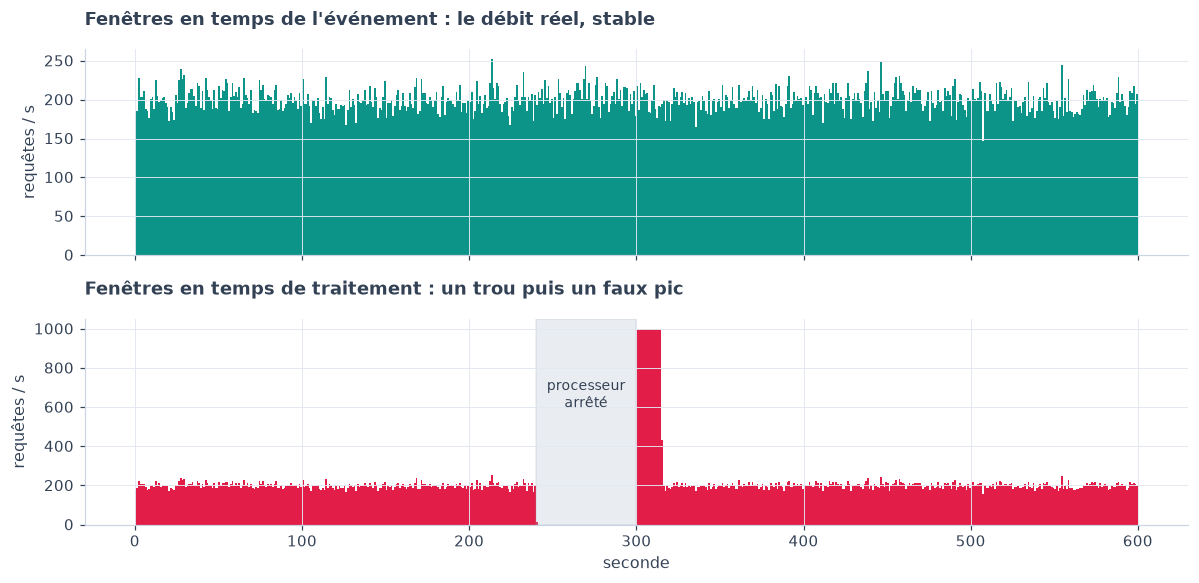

pic apparent en temps de traitement : 1000 req/s ; maximum réel : 252 req/s


In [2]:
T = 600
t_ev = np.sort(rng.uniform(0, T, 200 * T))
arret, reprise, vitesse = 240.0, 300.0, 5.0
# instant de traitement : les événements arrivés pendant l'arrêt attendent, puis la file se vide à 5x
t_tr = t_ev + 0.05
apres = t_ev >= arret
k = np.arange(apres.sum())
t_tr[apres] = np.maximum(t_ev[apres] + 0.05, reprise + k / (200 * vitesse))   # file vidée à 1 000 req/s
bins = np.arange(0, T + 1, 1)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True)
ax.hist(t_ev, bins=bins, color=TEAL)
ax.set_ylabel("requêtes / s"); ax.set_title("Fenêtres en temps de l'événement : le débit réel, stable")
ax2.hist(t_tr, bins=bins, color=ROSE)
ax2.axvspan(arret, reprise, color=GRAY, alpha=0.2)
ax2.text((arret + reprise) / 2, 600, "processeur\narrêté", ha="center", fontsize=9, color=SLATE)
ax2.set_ylabel("requêtes / s"); ax2.set_xlabel("seconde")
ax2.set_title("Fenêtres en temps de traitement : un trou puis un faux pic")
plt.tight_layout(); plt.show()
print(f"pic apparent en temps de traitement : {np.histogram(t_tr, bins)[0].max()} req/s ; "
      f"maximum réel : {np.histogram(t_ev, bins)[0].max()} req/s")

Le débit réel n'a jamais dépassé 250 requêtes par seconde ; en temps de traitement, on voit
une minute à zéro puis un pic à environ mille, deux artefacts du redéploiement. Les
fenêtres en temps de l'événement donnent la bonne réponse, et la même réponse à chaque
rejeu.

> **À retenir.** Le temps de traitement est simple mais dépend des aléas du pipeline ; le
> temps de l'événement décrit la réalité et rend le calcul déterministe. Dès qu'il peut y
> avoir du retard, il faut fenêtrer en temps de l'événement.

## 2. Les retardataires (section *Knowing when you're ready*)

En temps de l'événement, une difficulté apparaît : on ne sait **jamais** si l'on a reçu
tous les événements d'une fenêtre. On compte les requêtes de la 37e minute ; le temps a
passé, la plupart des événements reçus concernent maintenant les 38e et 39e minutes.
Quand déclarer la 37e minute terminée et émettre son compteur ? On peut attendre un
moment sans nouvel événement pour cette fenêtre, mais certains peuvent être retenus sur
une autre machine par une coupure réseau. Les **retardataires** (stragglers) qui arrivent
après la clôture laissent deux options :

- les **ignorer** (ils sont en principe peu nombreux), en comptant les événements écartés
  et en alertant si leur proportion grimpe ;
- publier une **correction**, la valeur mise à jour de la fenêtre, en retirant
  éventuellement la précédente.

Une heuristique courante est le **filigrane** (watermark) : un message qui affirme
« désormais, plus aucun événement antérieur à $t$ ». Ici, l'opérateur le calcule lui-même
comme « plus grand temps d'événement vu, moins une marge $L$ » (`st.WatermarkCounter`) :
une fenêtre est émise quand le filigrane dépasse sa fin. Plus la marge est grande, moins
il y a de retardataires écartés, mais plus le résultat arrive tard. Simulons 20 000
événements (10 par seconde, fenêtres de 10 s), avec un délai réseau log-normal de médiane
0,5 s et 1 % d'appareils hors ligne qui envoient leurs événements jusqu'à plusieurs
minutes plus tard.

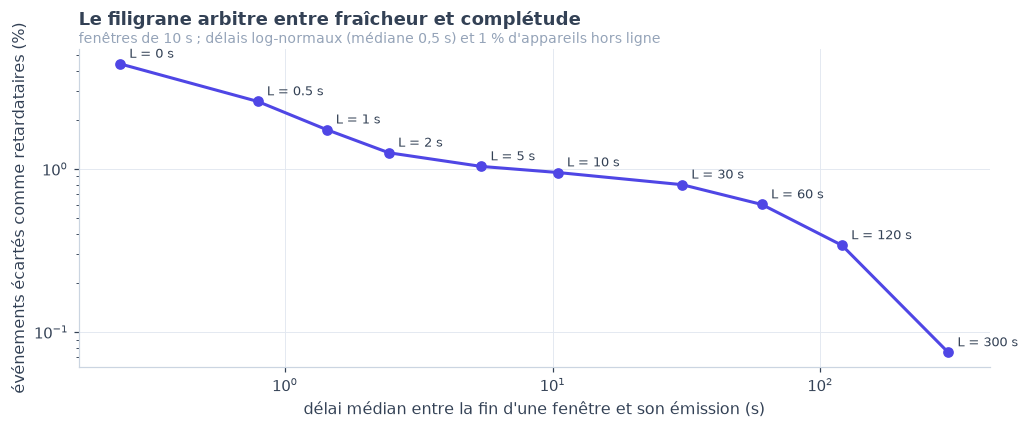

,écartés (%),délai médian d'émission (s),erreur moyenne par fenêtre,fenêtres ouvertes (max),corrections (politique update)
marge L (s),,,,,
0.0,4.40,0.45,4.40,1,880
0.5,2.59,0.91,2.59,2,518
1.0,1.74,1.43,1.74,2,348
2.0,1.26,2.44,1.25,2,251
5.0,1.03,5.41,1.03,2,207
10.0,0.95,10.45,0.95,2,190
30.0,0.80,30.45,0.80,4,160
60.0,0.60,60.45,0.60,7,121
120.0,0.34,120.46,0.34,13,68


In [3]:
n = 20_000
et = np.sort(rng.uniform(0, 2000, n))
delai = rng.lognormal(np.log(0.5), 0.8, n)
hors_ligne = rng.random(n) < 0.01
delai[hors_ligne] += rng.exponential(120, hors_ligne.sum())
arr = et + delai
vrai = st.tumbling_counts(et, 10)
rows = []
for L in [0, 0.5, 1, 2, 5, 10, 30, 60, 120, 300]:
    wc = st.WatermarkCounter(10, lateness=L, policy="drop").run(et, arr)
    finals = [r for r in wc.results if r.kind == "final"]
    lat = np.array([r.emitted_at - (r.window + 10) for r in finals])
    err = np.mean([abs(r.count - vrai[r.window]) for r in finals])
    wu = st.WatermarkCounter(10, lateness=L, policy="update").run(et, arr)
    rows.append({"marge L (s)": L, "écartés (%)": wc.dropped / n * 100, "délai médian d'émission (s)": np.median(lat),
                 "erreur moyenne par fenêtre": err, "fenêtres ouvertes (max)": wc.max_open,
                 "corrections (politique update)": sum(r.kind == "correction" for r in wu.results)})
W = pd.DataFrame(rows).set_index("marge L (s)")
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(W["délai médian d'émission (s)"], W["écartés (%)"], "o-", color=INDIGO)
for L, r in W.iterrows():
    ax.annotate(f"L = {L:g} s", (r["délai médian d'émission (s)"], r["écartés (%)"]), (6, 4),
                textcoords="offset points", fontsize=8.5, color=SLATE)
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("log")
ax.set_xlabel("délai médian entre la fin d'une fenêtre et son émission (s)")
ax.set_ylabel("événements écartés comme retardataires (%)")
ax.set_title("Le filigrane arbitre entre fraîcheur et complétude")
subtitle(ax, "fenêtres de 10 s ; délais log-normaux (médiane 0,5 s) et 1 % d'appareils hors ligne")
plt.tight_layout(); plt.show()
W.round(2)

Sans marge, 4,4 % des événements arrivent après la clôture de leur fenêtre : ce sont
surtout ceux des dernières secondes de chaque fenêtre, doublés par un événement plus
récent qui a fait avancer le filigrane. Le résultat est immédiat mais faux. Une marge
de quelques secondes absorbe le délai réseau ordinaire et ramène les pertes au voisinage
du 1 % d'appareils hors ligne ; pour récupérer ces derniers, il faut attendre plusieurs
minutes, et garder d'autant plus de fenêtres ouvertes en mémoire. La politique
« correction » évite de choisir : on émet tôt, puis on corrige (le nombre de corrections
décroît avec la marge), au prix de consommateurs capables de gérer des mises à jour.

**Plusieurs producteurs.** Si chaque producteur publie son propre filigrane, le
consommateur doit suivre chacun séparément et ne peut avancer qu'au **minimum** des
filigranes. Un producteur silencieux (en pause, en panne, ou simplement inactif) bloque
alors l'émission de toutes les fenêtres, et ajouter ou retirer des producteurs complique
encore la gestion.

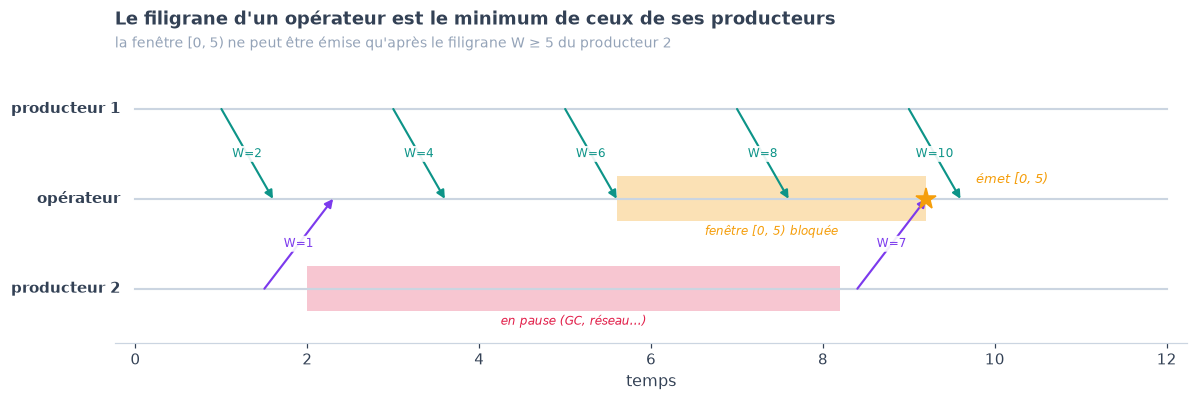

In [4]:
stt = SpaceTime(["producteur 1", "opérateur", "producteur 2"], t_max=12, width=11,
                title="Le filigrane d'un opérateur est le minimum de ceux de ses producteurs",
                subtitle="la fenêtre [0, 5) ne peut être émise qu'après le filigrane W ≥ 5 du producteur 2")
for t, w in [(1.0, 2), (3.0, 4), (5.0, 6), (7.0, 8), (9.0, 10)]:
    stt.msg("producteur 1", t, "opérateur", t + 0.6, f"W={w}", color=TEAL)
stt.msg("producteur 2", 1.5, "opérateur", 2.3, "W=1", color=VIOLET)
stt.span("producteur 2", 2.0, 8.2, "en pause (GC, réseau...)", color=ROSE, alpha=0.25)
stt.msg("producteur 2", 8.4, "opérateur", 9.2, "W=7", color=VIOLET)
stt.span("opérateur", 5.6, 9.2, "fenêtre [0, 5) bloquée", color=AMBER, alpha=0.3)
stt.event("opérateur", 9.2, "", kind="star")
stt.note(10.2, "opérateur", "émet [0, 5)", dy=0.22, color=AMBER)
stt.show()

> **À retenir.** On ne sait jamais si une fenêtre en temps de l'événement est complète.
> Un filigrane parie qu'elle l'est ; sa marge règle le compromis entre fraîcheur,
> complétude et mémoire. Les retardataires sont écartés (et comptés) ou donnent lieu à des
> corrections.

## 3. L'horloge de qui ? (section *Whose clock are you using, anyway?*)

L'horodatage se complique quand les événements sont mis en tampon à plusieurs endroits.
Une application mobile qui remonte des métriques d'usage peut être utilisée hors
connexion : elle garde les événements et les envoie au retour du réseau, des heures ou
des jours plus tard. Pour les consommateurs, ce sont des retardataires extrêmes.

Le bon horodatage est l'instant de l'interaction selon l'**horloge de l'appareil**, mais
celle-ci est souvent fausse (réglée à la main, volontairement ou non, chapitre
8). L'heure de réception par le serveur est fiable mais décrit mal
l'interaction. Une parade consiste à enregistrer **trois horodatages** :

1. l'instant de l'événement, selon l'horloge de l'appareil ($e_d$) ;
2. l'instant de l'envoi au serveur, selon l'horloge de l'appareil ($s_d$) ;
3. l'instant de réception, selon l'horloge du serveur ($r_s$).

$r_s - s_d$ estime le décalage entre les deux horloges (si le délai réseau est
négligeable) ; on corrige alors $e_d$ : $\hat{e} = e_d + (r_s - s_d)$. L'erreur restante
est le délai réseau, plus la variation du décalage de l'appareil entre l'événement et
l'envoi. Simulons 5 000 événements d'appareils dont les horloges sont décalées de
quelques secondes à plusieurs heures (et dérivent de 50 ppm), avec des envois différés
jusqu'à deux jours.

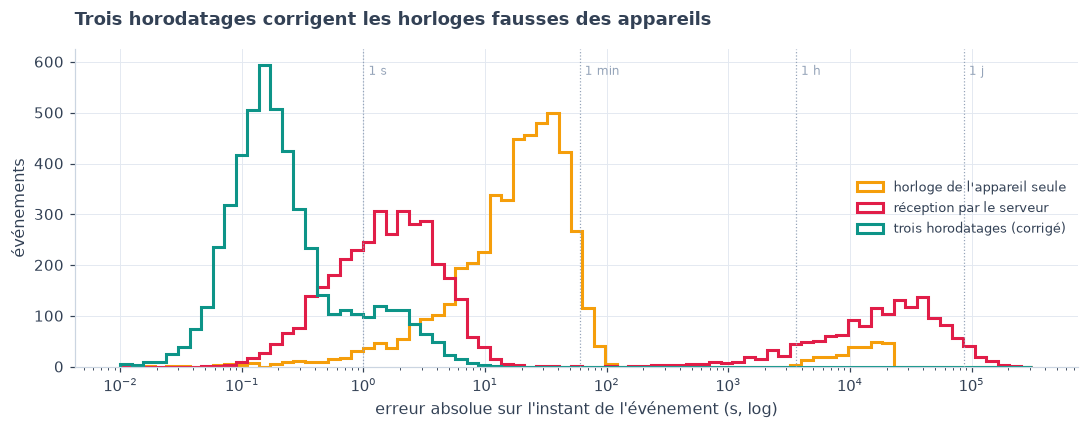

,médiane |erreur| (s),p99 |erreur| (s)
horloge de l'appareil seule,21.47,18103.90
réception par le serveur,2.79,95412.21
trois horodatages (corrigé),0.18,4.59


In [5]:
m = 5000
vrai_t = rng.uniform(0, 86400 * 3, m)
decalage = rng.normal(0, 30, m)
faux = rng.random(m) < 0.05
decalage[faux] += rng.choice([-1, 1], faux.sum()) * rng.uniform(3600, 6 * 3600, faux.sum())   # fuseau mal réglé
derive = 50e-6
attente = np.where(rng.random(m) < 0.7, rng.exponential(2, m), rng.exponential(8 * 3600, m))  # hors ligne parfois
envoi = vrai_t + attente
reseau = rng.lognormal(np.log(0.15), 0.6, m)
e_d = vrai_t + decalage
s_d = envoi + decalage + derive * attente                 # le décalage a dérivé pendant l'attente
r_s = envoi + reseau
corrige = e_d + (r_s - s_d)
erreurs = {"horloge de l'appareil seule": e_d - vrai_t, "réception par le serveur": r_s - vrai_t,
           "trois horodatages (corrigé)": corrige - vrai_t}
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.logspace(-2, 5.5, 80)
for (nom, e), c in zip(erreurs.items(), [AMBER, ROSE, TEAL]):
    ax.hist(np.abs(e), bins=bins, histtype="step", lw=2, color=c, label=nom)
ax.set_xscale("log")
ax.set_xlabel("erreur absolue sur l'instant de l'événement (s, log)"); ax.set_ylabel("événements")
ax.set_title("Trois horodatages corrigent les horloges fausses des appareils")
for x, lab in [(1, "1 s"), (60, "1 min"), (3600, "1 h"), (86400, "1 j")]:
    ax.axvline(x, color=GRAY, lw=0.8, ls=":"); ax.text(x * 1.1, ax.get_ylim()[1] * 0.92, lab, fontsize=8, color=GRAY)
ax.legend(loc="center right", fontsize=8.5)
plt.tight_layout(); plt.show()
pd.DataFrame({nom: {"médiane |erreur| (s)": np.median(np.abs(e)), "p99 |erreur| (s)": np.percentile(np.abs(e), 99)}
              for nom, e in erreurs.items()}).T.round(2)

L'horloge de l'appareil se trompe de quelques dizaines de secondes typiquement, et de
plusieurs heures pour les appareils mal réglés ; l'heure de réception est fausse de la
durée de mise en tampon (des heures pour les appareils hors ligne). La correction ramène
l'erreur médiane au délai réseau (une fraction de seconde) ; son p99 reste de quelques
secondes, dû à la dérive de l'horloge pendant les longues périodes hors ligne. Ce
problème n'est pas propre au flux : un traitement par lots raisonne sur le temps de la
même façon, on le remarque simplement moins.

> **À retenir.** L'horloge de l'appareil date bien l'interaction mais peut être fausse ;
> celle du serveur est juste mais date la réception. Enregistrer trois horodatages permet
> d'estimer et de corriger le décalage.

## 4. Les types de fenêtres (section *Types of windows*)

Une fois l'horodatage choisi, reste à définir les fenêtres sur lesquelles agréger
(compter, moyenner). Quatre types sont courants :

- **fixe** (tumbling) : longueur fixe, chaque événement dans **exactement une** fenêtre ;
  on l'implémente en arrondissant l'horodatage à la minute inférieure (pour des fenêtres
  d'une minute) ;
- **par sauts** (hopping) : longueur fixe, mais les fenêtres se **chevauchent** pour lisser
  (5 minutes, avec un saut de 1 minute) ; on l'implémente en calculant des fenêtres fixes
  d'une minute puis en agrégeant cinq fenêtres voisines ;
- **glissante** (sliding) : tous les événements à moins d'un intervalle donné les uns des
  autres, sans frontières fixes ; on garde un tampon d'événements trié par temps, dont on
  retire ceux qui expirent ;
- **de session** : pas de durée fixe ; on regroupe les événements d'un même utilisateur
  proches dans le temps, et la session se termine après une période d'inactivité (par
  exemple 30 minutes). La « sessionisation » est un besoin classique de l'analytique web.

La figure place une vingtaine d'événements de deux utilisateurs dans chaque type de
fenêtre (`st.tumbling_counts`, `st.hopping_counts`, `st.sliding_counts`, `st.sessionize`).

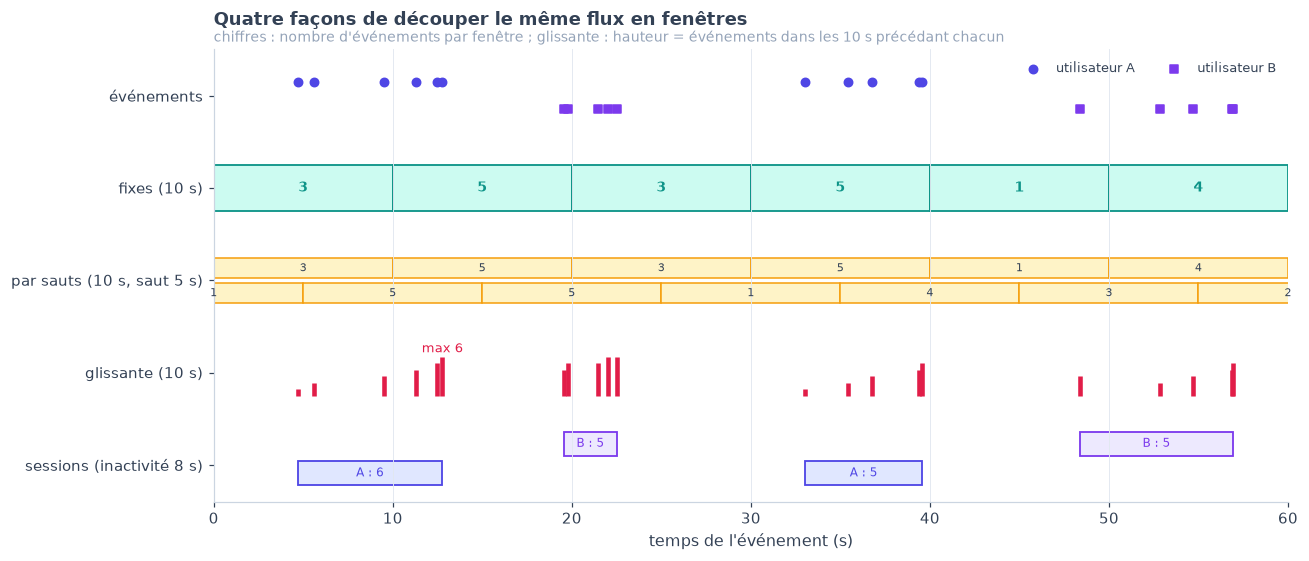

In [6]:
r = np.random.default_rng(7)
ev_a = np.sort(np.concatenate([r.uniform(2, 14, 6), r.uniform(33, 41, 5)]))
ev_b = np.sort(np.concatenate([r.uniform(17, 27, 5), r.uniform(46, 57, 5)]))
tous = np.sort(np.concatenate([ev_a, ev_b]))
fig, ax = plt.subplots(figsize=(12, 5.2))
rangs = {"événements": 4.4, "fixes (10 s)": 3.4, "par sauts (10 s, saut 5 s)": 2.4,
         "glissante (10 s)": 1.4, "sessions (inactivité 8 s)": 0.4}
ax.scatter(ev_a, np.full(ev_a.size, 4.55), color=INDIGO, s=30, zorder=3, label="utilisateur A")
ax.scatter(ev_b, np.full(ev_b.size, 4.25), color=VIOLET, s=30, marker="s", zorder=3, label="utilisateur B")
for w, c in st.tumbling_counts(tous, 10).items():
    ax.add_patch(Rectangle((w, 3.15), 10, 0.5, facecolor=LIGHT[TEAL], edgecolor=TEAL, lw=1.2))
    ax.text(w + 5, 3.4, str(c), ha="center", va="center", fontsize=9, color=TEAL, fontweight="bold")
for i, (w, c) in enumerate(st.hopping_counts(tous, 10, 5).items()):
    y = 2.15 + 0.27 * (i % 2)
    ax.add_patch(Rectangle((w, y), 10, 0.22, facecolor=LIGHT[AMBER], edgecolor=AMBER, lw=1.0))
    ax.text(w + 5, y + 0.11, str(c), ha="center", va="center", fontsize=7.5, color=SLATE)
sl = st.sliding_counts(tous, 10)
ax.vlines(tous, 1.15, 1.15 + 0.07 * sl, color=ROSE, lw=3)
ax.text(tous[np.argmax(sl)], 1.2 + 0.07 * sl.max(), f"max {sl.max()}", fontsize=8.5, color=ROSE, ha="center")
for k, ev, c in [("A", ev_a, INDIGO), ("B", ev_b, VIOLET)]:
    for _, s0, s1, nn in st.sessionize([(k, t) for t in ev], gap=8):
        ax.add_patch(Rectangle((s0, 0.18 if k == "A" else 0.5), max(s1 - s0, 0.4), 0.26, facecolor=LIGHT[c],
                               edgecolor=c, lw=1.2))
        ax.text((s0 + s1) / 2, 0.31 if k == "A" else 0.63, f"{k} : {nn}", ha="center", va="center", fontsize=8, color=c)
ax.set_yticks(list(rangs.values()), list(rangs.keys()))
ax.set_ylim(0, 4.9); ax.set_xlim(0, 60)
ax.set_xlabel("temps de l'événement (s)")
ax.set_title("Quatre façons de découper le même flux en fenêtres")
subtitle(ax, "chiffres : nombre d'événements par fenêtre ; glissante : hauteur = événements dans les 10 s précédant chacun")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", fontsize=8.5, ncol=2)
plt.tight_layout(); plt.show()

Les fenêtres fixes partitionnent le temps ; les fenêtres par sauts comptent chaque
événement deux fois (longueur / saut = 2) et lissent ; la fenêtre glissante attache à
chaque événement le nombre de ses voisins des 10 dernières secondes, sans frontière
arbitraire (deux événements à 9 s d'écart sont toujours ensemble, alors qu'une frontière
fixe peut les séparer) ; les sessions suivent l'activité de chaque utilisateur, avec des
durées variables.

**L'état d'une fenêtre.** Les opérations fenêtrées gardent un état temporaire. Pour un
simple compteur, il est de taille fixe quels que soient la largeur de la fenêtre et le
nombre d'événements ; mais une fenêtre glissante (et les jointures du cours 7) doit
**garder les événements** jusqu'à leur expiration, soit en moyenne (loi de Little)
débit × largeur. Ordres de grandeur pour un flux de 5 000 événements par seconde :

In [7]:
largeurs = np.array([1, 10, 60, 300, 3600, 86400])
debit = 5000
etat = pd.DataFrame({
    "fixe (compteurs)": np.full(largeurs.size, 2),
    "par sauts, saut 1/10 de la largeur (compteurs)": np.full(largeurs.size, 10),
    "glissante (événements en mémoire)": debit * largeurs,
    "mémoire glissante à 100 o/événement": [f"{debit * l * 100 / 1e6:,.1f} Mo".replace(",", " ") for l in largeurs],
}, index=pd.Index(["1 s", "10 s", "1 min", "5 min", "1 h", "1 j"], name="largeur"))
etat

,fixe (compteurs),"par sauts, saut 1/10 de la largeur (compteurs)",glissante (événements en mémoire),mémoire glissante à 100 o/événement
largeur,,,,
1 s,2,10,5000,0.5 Mo
10 s,2,10,50000,5.0 Mo
1 min,2,10,300000,30.0 Mo
5 min,2,10,1500000,150.0 Mo
1 h,2,10,18000000,1 800.0 Mo
1 j,2,10,432000000,43 200.0 Mo


Un compteur par fenêtre ne coûte presque rien ; une fenêtre glissante d'une journée sur
ce flux demande plus de 40 Go d'événements en mémoire (ou sur disque). Il faut donc
dimensionner les machines de traitement pour cet état, ou reformuler l'agrégat pour qu'il
soit incrémental (un compteur par seconde, sommé sur la fenêtre, transforme la fenêtre
glissante en fenêtre par sauts de pas fin).

> **À retenir.** Fixes, par sauts, glissantes, sessions : quatre découpages pour quatre
> besoins. Un agrégat incrémental garde un état constant ; une fenêtre qui doit garder
> ses événements consomme débit × largeur.

## Synthèse

- Le **temps de l'événement** décrit la réalité et rend le calcul déterministe ; le
  **temps de traitement**, plus simple, produit des artefacts dès que le pipeline prend du
  retard (redéploiement, rattrapage).
- En temps de l'événement, une fenêtre n'est jamais sûrement complète : un **filigrane**
  parie, et sa marge arbitre entre fraîcheur, complétude et mémoire ; les
  **retardataires** sont écartés ou corrigés ; avec plusieurs producteurs, le filigrane est
  le minimum des leurs.
- Les horloges des appareils sont peu fiables : **trois horodatages** permettent d'estimer
  et de corriger leur décalage.
- Fenêtres **fixes**, **par sauts**, **glissantes** et **de session** ; leur état va d'un
  compteur à débit × largeur événements.
- Liens : horloges et leur synchronisation (chapitre 8), loi de Little et files
  d'attente (chapitre 1), traitement par lots sur les horodatages
  (chapitre 10). Le cours 7 traite des jointures entre flux, où le temps joue
  aussi un rôle, et de la tolérance aux pannes.